# Assignment No. 2: Decision Tree and Support Vector Machine (SVM)

**Dataset:** Breast Cancer Wisconsin (Diagnostic) - built into Scikit-learn  
**Task:** Binary classification (Malignant vs Benign)  
**Models:** SVM (implemented from scratch with NumPy) and Decision Tree (Scikit-learn)  
**Libraries:** NumPy, Pandas, Matplotlib, Seaborn, Scikit-learn

## 1. Import Libraries

In [1]:
import json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

sns.set_style('whitegrid')
os.makedirs('figs', exist_ok=True)
np.random.seed(42)

## 2. Load and Explore the Dataset

In [2]:
data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)
df['target'] = data.target          # 0 = malignant, 1 = benign

print('Shape:', df.shape)
print('Missing values:', int(df.isnull().sum().sum()))
print('Classes:', dict(zip(data.target_names, np.bincount(data.target))))
df.head()

Shape: (569, 31)
Missing values: 0
Classes: {np.str_('malignant'): np.int64(212), np.str_('benign'): np.int64(357)}


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [3]:
df.describe().T.head(10)

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.98100,11.70000,13.37000,15.78000,28.11000
mean texture,569.0,19.289649,4.301036,9.71000,16.17000,18.84000,21.80000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.79000,75.17000,86.24000,104.10000,188.50000
mean area,569.0,654.889104,351.914129,143.50000,420.30000,551.10000,782.70000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.05263,0.08637,0.09587,0.10530,0.16340
mean compactness,569.0,0.104341,0.052813,0.01938,0.06492,0.09263,0.13040,0.34540
mean concavity,569.0,0.088799,0.079720,0.00000,0.02956,0.06154,0.13070,0.42680
mean concave points,569.0,0.048919,0.038803,0.00000,0.02031,0.03350,0.07400,0.20120
mean symmetry,569.0,0.181162,0.027414,0.10600,0.16190,0.17920,0.19570,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.04996,0.05770,0.06154,0.06612,0.09744


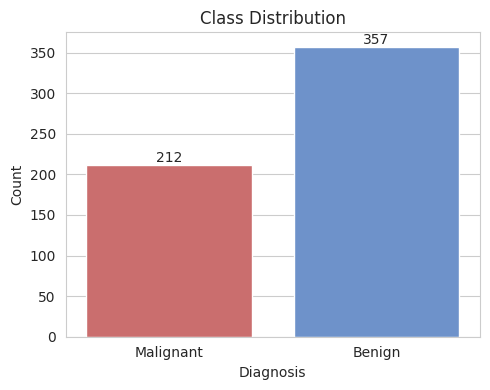

In [4]:
# Class distribution
plt.figure(figsize=(5, 4))
ax = sns.countplot(x=df['target'].map({0: 'Malignant', 1: 'Benign'}), hue=df['target'].map({0: 'Malignant', 1: 'Benign'}),
                   palette=['#d95f5f', '#5f8fd9'], legend=False)
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha='center', va='bottom')
plt.title('Class Distribution'); plt.xlabel('Diagnosis'); plt.ylabel('Count')
plt.tight_layout(); plt.savefig('figs/class_distribution.png', dpi=150); plt.show()

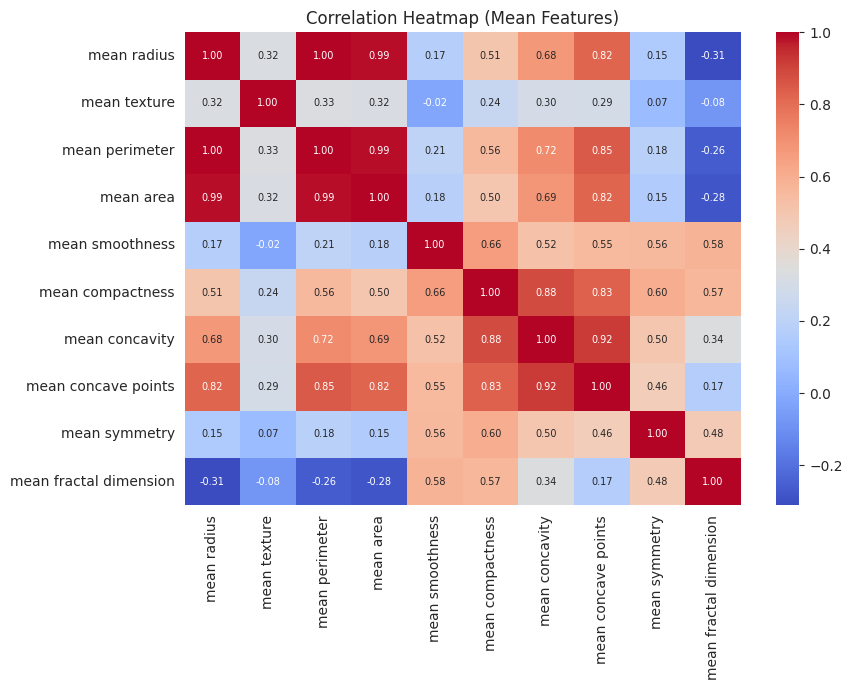

In [5]:
# Correlation heatmap of the first 10 (mean) features
plt.figure(figsize=(9, 7))
sns.heatmap(df.iloc[:, :10].corr(), annot=True, fmt='.2f', cmap='coolwarm', annot_kws={'size': 7})
plt.title('Correlation Heatmap (Mean Features)')
plt.tight_layout(); plt.savefig('figs/correlation_heatmap.png', dpi=150); plt.show()

## 3. Data Preprocessing

In [6]:
X = df.drop('target', axis=1).values
y = df['target'].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# Standardize features (important for SVM and gradient descent)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print('Train size:', X_train.shape, ' Test size:', X_test.shape)

Train size: (455, 30)  Test size: (114, 30)


## 4. Support Vector Machine (SVM) - From Scratch

A linear SVM finds the hyperplane **w . x + b = 0** that separates the two classes with the largest margin.
Labels are converted to **-1 / +1**. We follow these steps:

1. **Initialize the parameters** - weights `w` and bias `b` start at zero.
2. **Predict the output** - `f(x) = w . x + b`, and the class is `sign(f(x))`.
3. **Loss function** - Hinge loss with L2 regularization:  
   `J(w, b) = (lambda/2) * ||w||^2 + (1/n) * sum( max(0, 1 - y_i * (w . x_i + b)) )`
4. **Gradient descent** - compute gradients. For samples with `y_i * f(x_i) < 1` (margin violated):  
   `dw = lambda * w - (1/n) * sum(y_i * x_i)` and `db = -(1/n) * sum(y_i)`.  
   For correctly classified samples outside the margin, only `lambda * w` contributes.
5. **Update the parameters** - `w = w - lr * dw`, `b = b - lr * db`, repeated for many iterations.

In [7]:
class SVM_Scratch:
    def __init__(self, learning_rate=0.1, lambda_param=0.01, n_iters=500):
        self.lr = learning_rate
        self.lam = lambda_param
        self.n_iters = n_iters
        self.w = None
        self.b = None
        self.loss_history = []

    # Step 1: Initialize the parameters
    def initialize_parameters(self, n_features):
        self.w = np.zeros(n_features)
        self.b = 0.0

    # Step 2: Predict the output (raw score)
    def decision_function(self, X):
        return np.dot(X, self.w) + self.b

    def predict(self, X):
        return np.where(self.decision_function(X) >= 0, 1, 0)   # back to 0/1 labels

    # Step 3: Loss function (hinge loss + L2 regularization)
    def compute_loss(self, X, y_svm):
        margins = y_svm * self.decision_function(X)
        hinge = np.maximum(0, 1 - margins)
        return 0.5 * self.lam * np.dot(self.w, self.w) + hinge.mean()

    # Step 4: Gradient descent (compute gradients)
    def compute_gradients(self, X, y_svm):
        n = X.shape[0]
        margins = y_svm * self.decision_function(X)
        violated = margins < 1                       # samples inside/violating the margin
        dw = self.lam * self.w - (X[violated].T @ y_svm[violated]) / n
        db = -np.sum(y_svm[violated]) / n
        return dw, db

    # Step 5: Update the parameters
    def fit(self, X, y):
        y_svm = np.where(y == 0, -1, 1)               # 0/1 -> -1/+1
        self.initialize_parameters(X.shape[1])
        for i in range(self.n_iters):
            dw, db = self.compute_gradients(X, y_svm)
            self.w -= self.lr * dw
            self.b -= self.lr * db
            self.loss_history.append(self.compute_loss(X, y_svm))
        return self

Initial loss : 0.3345
Final loss   : 0.0617


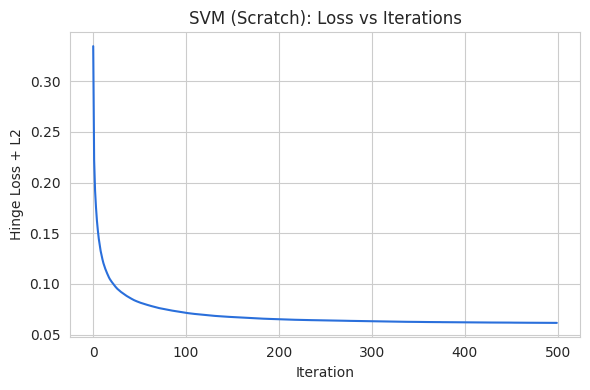

In [8]:
svm_scratch = SVM_Scratch(learning_rate=0.1, lambda_param=0.01, n_iters=500)
svm_scratch.fit(X_train_s, y_train)

print('Initial loss :', round(svm_scratch.loss_history[0], 4))
print('Final loss   :', round(svm_scratch.loss_history[-1], 4))

plt.figure(figsize=(6, 4))
plt.plot(svm_scratch.loss_history, color='#2a6fdb')
plt.title('SVM (Scratch): Loss vs Iterations'); plt.xlabel('Iteration'); plt.ylabel('Hinge Loss + L2')
plt.tight_layout(); plt.savefig('figs/svm_loss_curve.png', dpi=150); plt.show()

In [9]:
y_pred_svm = svm_scratch.predict(X_test_s)
print('SVM (scratch) test accuracy:', round(accuracy_score(y_test, y_pred_svm), 4))

SVM (scratch) test accuracy: 0.9825


## 5. Decision Tree
A Decision Tree splits the data using feature thresholds that best reduce impurity (Gini index). We tune `max_depth`
and `min_samples_leaf` with 5-fold cross-validation to avoid overfitting.

In [10]:
param_grid = {'max_depth': [2, 3, 4, 5, 6, 8, None], 'min_samples_leaf': [1, 2, 4, 8]}
grid = GridSearchCV(DecisionTreeClassifier(criterion='gini', random_state=42), param_grid, cv=5, scoring='accuracy')
grid.fit(X_train, y_train)

print('Best parameters:', grid.best_params_)
print('Best CV accuracy:', round(grid.best_score_, 4))

dt = grid.best_estimator_
y_pred_dt = dt.predict(X_test)
print('Decision Tree test accuracy:', round(accuracy_score(y_test, y_pred_dt), 4))

Best parameters: {'max_depth': 4, 'min_samples_leaf': 1}
Best CV accuracy: 0.9385
Decision Tree test accuracy: 0.9386


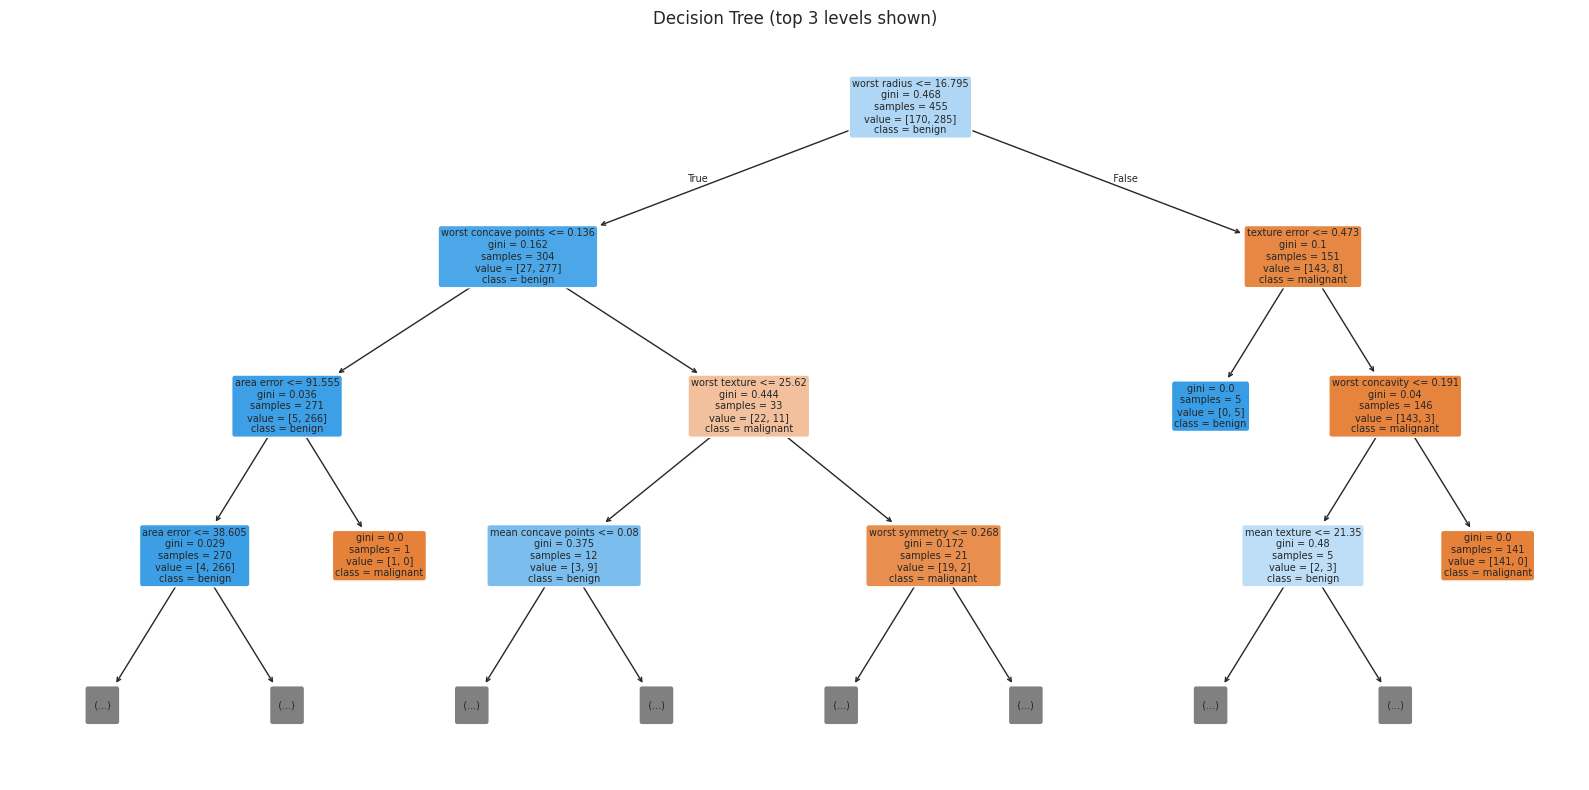

In [11]:
plt.figure(figsize=(16, 8))
plot_tree(dt, feature_names=data.feature_names, class_names=data.target_names,
          filled=True, rounded=True, fontsize=7, max_depth=3)
plt.title('Decision Tree (top 3 levels shown)')
plt.tight_layout(); plt.savefig('figs/decision_tree.png', dpi=150); plt.show()

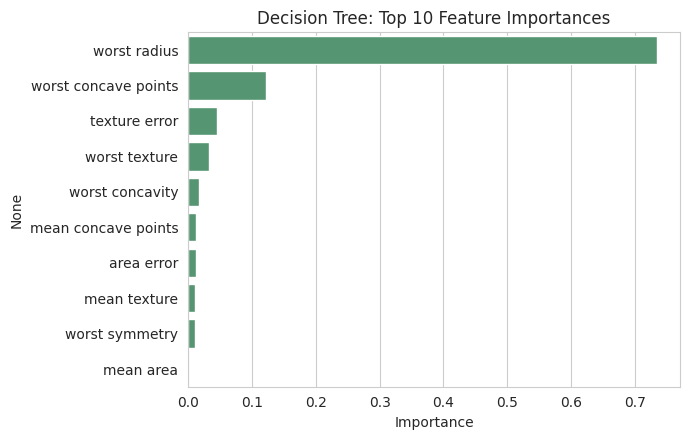

In [12]:
# Feature importance
imp = pd.Series(dt.feature_importances_, index=data.feature_names).sort_values(ascending=False).head(10)
plt.figure(figsize=(7, 4.5))
sns.barplot(x=imp.values, y=imp.index, color='#4c9f70')
plt.title('Decision Tree: Top 10 Feature Importances'); plt.xlabel('Importance')
plt.tight_layout(); plt.savefig('figs/feature_importance.png', dpi=150); plt.show()

## 6. Verification with Scikit-learn SVC
To confirm that our scratch implementation is correct, we compare it with Scikit-learn's linear `SVC`.

In [13]:
svc = SVC(kernel='linear', C=1.0, random_state=42)
svc.fit(X_train_s, y_train)
y_pred_svc = svc.predict(X_test_s)
print('Scikit-learn linear SVC test accuracy:', round(accuracy_score(y_test, y_pred_svc), 4))

Scikit-learn linear SVC test accuracy: 0.9737


## 7. Evaluation: Accuracy, Precision, Recall, F1-score

In [14]:
def evaluate(y_true, y_pred):
    return {'Accuracy': accuracy_score(y_true, y_pred),
            'Precision': precision_score(y_true, y_pred),
            'Recall': recall_score(y_true, y_pred),
            'F1-score': f1_score(y_true, y_pred)}

results = pd.DataFrame({
    'SVM (Scratch)': evaluate(y_test, y_pred_svm),
    'Decision Tree': evaluate(y_test, y_pred_dt),
    'SVC (Scikit-learn)': evaluate(y_test, y_pred_svc),
}).T.round(4)
results

,Accuracy,Precision,Recall,F1-score
SVM (Scratch),0.9825,0.9861,0.9861,0.9861
Decision Tree,0.9386,0.9577,0.9444,0.9510
SVC (Scikit-learn),0.9737,0.9859,0.9722,0.9790


In [15]:
print('--- SVM (Scratch) ---')
print(classification_report(y_test, y_pred_svm, target_names=data.target_names))
print('--- Decision Tree ---')
print(classification_report(y_test, y_pred_dt, target_names=data.target_names))

--- SVM (Scratch) ---
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

--- Decision Tree ---
              precision    recall  f1-score   support

   malignant       0.91      0.93      0.92        42
      benign       0.96      0.94      0.95        72

    accuracy                           0.94       114
   macro avg       0.93      0.94      0.93       114
weighted avg       0.94      0.94      0.94       114



## 8. Confusion Matrices

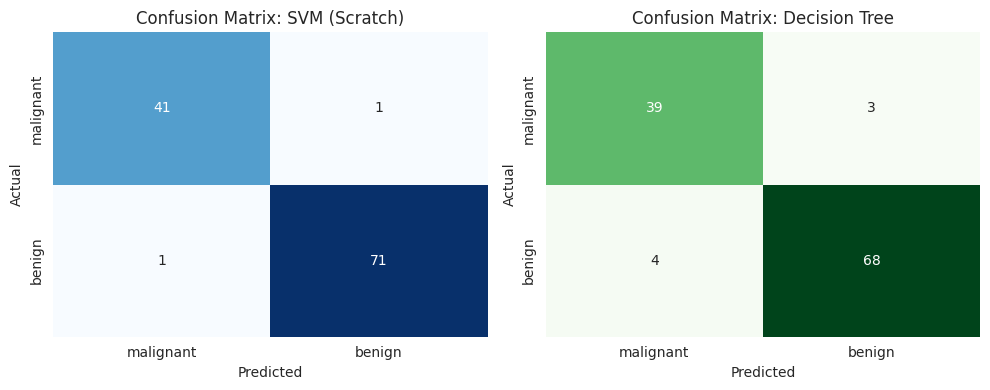

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, pred, cmap) in zip(axes, [('SVM (Scratch)', y_pred_svm, 'Blues'), ('Decision Tree', y_pred_dt, 'Greens')]):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap, cbar=False, ax=ax,
                xticklabels=data.target_names, yticklabels=data.target_names)
    ax.set_title(f'Confusion Matrix: {name}'); ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
plt.tight_layout(); plt.savefig('figs/confusion_matrices.png', dpi=150); plt.show()

## 9. Comparative Analysis

5-fold CV accuracy -> SVM (linear): 0.9719 | Decision Tree: 0.9209


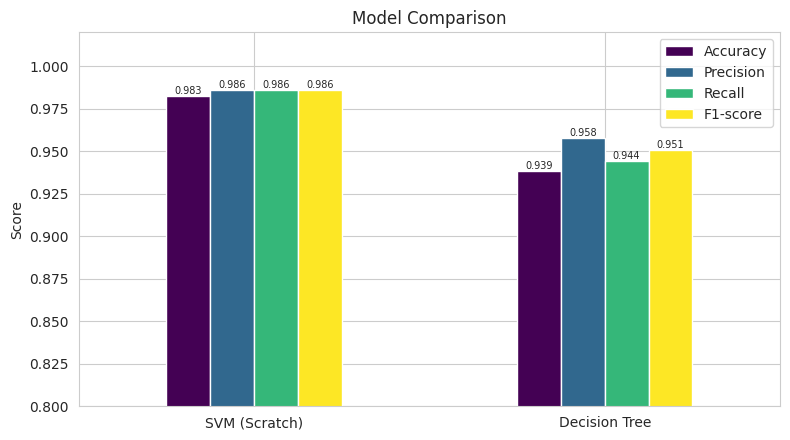

In [17]:
# Cross-validation on the full dataset (fair comparison)
from sklearn.pipeline import make_pipeline
cv_svm = cross_val_score(make_pipeline(StandardScaler(), SVC(kernel='linear')), X, y, cv=5).mean()
cv_dt = cross_val_score(DecisionTreeClassifier(**grid.best_params_, random_state=42), X, y, cv=5).mean()
print('5-fold CV accuracy -> SVM (linear):', round(cv_svm, 4), '| Decision Tree:', round(cv_dt, 4))

ax = results.loc[['SVM (Scratch)', 'Decision Tree']].plot(kind='bar', figsize=(8, 4.5), colormap='viridis', rot=0)
ax.set_ylim(0.8, 1.02); ax.set_title('Model Comparison'); ax.set_ylabel('Score')
for c in ax.containers:
    ax.bar_label(c, fmt='%.3f', fontsize=7)
plt.tight_layout(); plt.savefig('figs/model_comparison.png', dpi=150); plt.show()

In [18]:
# Save metrics for the report
cms = {'svm': confusion_matrix(y_test, y_pred_svm).tolist(), 'dt': confusion_matrix(y_test, y_pred_dt).tolist()}
out = {'results': results.to_dict('index'), 'cm': cms, 'best_params': {k: (None if v is None else int(v)) for k, v in grid.best_params_.items()},
       'cv_svm': float(cv_svm), 'cv_dt': float(cv_dt), 'cv_dt_grid': float(grid.best_score_),
       'loss_first': float(svm_scratch.loss_history[0]), 'loss_last': float(svm_scratch.loss_history[-1]),
       'n_train': int(len(X_train)), 'n_test': int(len(X_test)),
       'top_features': imp.head(3).index.tolist(), 'top_importance': [float(v) for v in imp.head(3).values],
       'depth': int(dt.get_depth()), 'leaves': int(dt.get_n_leaves())}
json.dump(out, open('metrics.json', 'w'), indent=2)
print(json.dumps(out['results'], indent=2))

{
  "SVM (Scratch)": {
    "Accuracy": 0.9825,
    "Precision": 0.9861,
    "Recall": 0.9861,
    "F1-score": 0.9861
  },
  "Decision Tree": {
    "Accuracy": 0.9386,
    "Precision": 0.9577,
    "Recall": 0.9444,
    "F1-score": 0.951
  },
  "SVC (Scikit-learn)": {
    "Accuracy": 0.9737,
    "Precision": 0.9859,
    "Recall": 0.9722,
    "F1-score": 0.979
  }
}


## 10. Conclusion
Both models perform very well on this dataset. The results table and confusion matrices above show their accuracy,
precision, recall and F1-score. The SVM works on standardized features and finds a maximum-margin boundary, while the
Decision Tree gives rules that are easy to read and explain. See the Word report for the full comparison.